In [1]:
%pip install -q pandas matplotlib nltk wordcloud scikit-learn pyLDAvis requests

In [2]:
import re
import zipfile
import requests
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

## Load the dataset

In [3]:
# Download the GitHub dataset repository.
data_dir = Path("health_headlines_dataset")
data_dir.mkdir(exist_ok=True)

zip_path = data_dir / "dataset.zip"
urls = [
    "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/archive/refs/heads/main.zip",
    "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/archive/refs/heads/master.zip"
]

if not list(data_dir.rglob("*.csv")) and not list(data_dir.rglob("*.json")):
    downloaded = False
    for url in urls:
        response = requests.get(url, timeout=60)
        if response.status_code == 200:
            zip_path.write_bytes(response.content)
            with zipfile.ZipFile(zip_path, "r") as z:
                z.extractall(data_dir)
            zip_path.unlink()
            downloaded = True
            break
    if not downloaded:
        raise RuntimeError("Dataset download failed. Download the dataset from the GitHub link and place its CSV/JSON file in the health_headlines_dataset folder.")

files = list(data_dir.rglob("*.csv")) + list(data_dir.rglob("*.json"))
print("Dataset files found:")
for f in files:
    print(f)

Dataset files found:
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Patient_Safety_Related_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Patient_Safety_Journals_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Pain_Management_Journals_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Antibiotic_Resistance_News_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Antibiotic_Resistance_Perspective_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Substance_Abuse_and_Addiction_News_Headlines.csv
health_headlines_dataset/Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master/Patient_Safety_News_Headlines.csv
health_

In [4]:
# Read the first available CSV or JSON file.
if not files:
    raise FileNotFoundError("No CSV or JSON file found in the dataset folder.")

file_path = files[0]
if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path)
else:
    df = pd.read_json(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (5911, 4)
Columns: ['Date', 'Source', 'Headlines', 'Teaser']


,Date,Source,Headlines,Teaser
0,"November, 2001",Topics in Advanced Practice Nursing eJournal,Preparing for a Successful JCAHO Visit,Learn what you can do to make a JCAHO visit su...
1,"December, 2001",Drugs & Therapy Perspectives,First Reports of Adverse Drug Reactions (ADRs)...,Read an overview of first published case repor...
2,"January, 2002",Pharmacotherapy,Use of Potentially Inappropriate Drugs in Nurs...,Use of potentially inappropriate drugs was pre...
3,"February, 2002",Pharmacotherapy,"Clinical Pharmacy Services, Hospital Pharmacy ...","These findings suggest that at least 90,895 pa..."
4,"March, 2002",Southern Medical Journal,Accidental Injection of Epinephrine From an Au...,Although some injection injuries must be treat...


In [5]:
# Combine the headline/title/teaser text columns.
text_columns = [
    col for col in df.columns
    if re.search(r"headline|title|teaser|text|description|summary", str(col), re.I)
]

if not text_columns:
    text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()

print("Text columns used:", text_columns)

df["text"] = (
    df[text_columns].fillna("").astype(str).agg(" ".join, axis=1).str.strip()
)
df = df[df["text"] != ""].copy()
df.reset_index(drop=True, inplace=True)

Text columns used: ['Headlines', 'Teaser']


## Task 1: Data Preprocessing and Cleaning

The text is converted to lowercase, punctuation is removed, and the text is tokenized. Stop words are removed and the remaining words are lemmatized.

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)   # Remove punctuation and numbers
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)             # Tokenization
    tokens = [
        lemmatizer.lemmatize(word)            # Lemmatization
        for word in tokens
        if word not in stop_words and len(word) > 2  # Stop-word removal
    ]
    return tokens

df["tokens"] = df["text"].apply(preprocess_text)
df["cleaned_text"] = df["tokens"].apply(lambda x: " ".join(x))

# Display a few cleaned text samples.
for sample in df["cleaned_text"].head(5):
    print(sample)

preparing successful jcaho visit learn make jcaho visit successful
first report adverse drug reaction adrs recent week read overview first published case report adrs identified international literature recent week
use potentially inappropriate drug nursing home use potentially inappropriate drug prevalent admission among resident stayed least day
clinical pharmacy service hospital pharmacy staffing finding suggest least patient annually harmed medication error general hospital
accidental injection epinephrine autoinjector although injection injury must treated emergency facility many treated home


## Task 2: Exploratory Text Analysis and Word Visualization

### Word frequency distribution

In [7]:
all_words = [word for tokens in df["tokens"] for word in tokens]
word_freq = Counter(all_words)

frequency_df = pd.DataFrame(
    word_freq.most_common(),
    columns=["Word", "Frequency"]
)
display(frequency_df.head(20))

,Word,Frequency
0,patient,2285
1,risk,1225
2,new,1163
3,drug,1113
4,study,1052
5,may,731
6,safety,702
7,care,631
8,use,616
9,hospital,605


### Word cloud

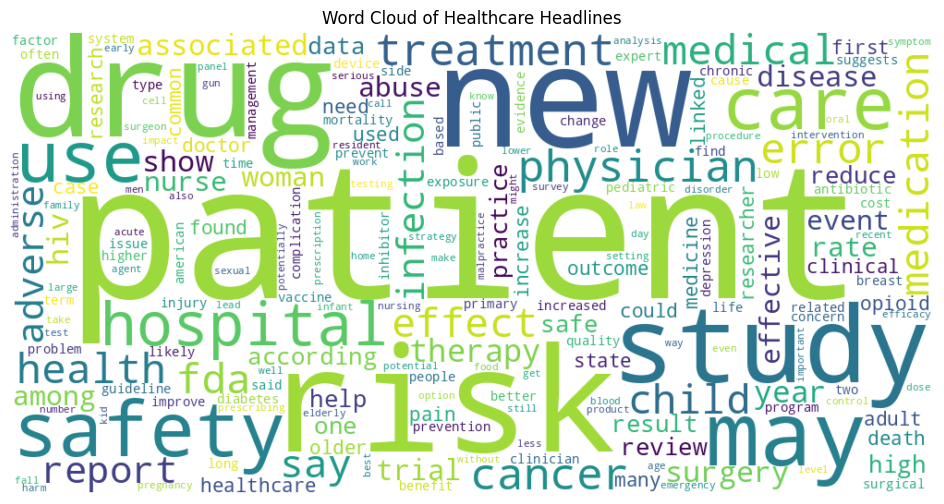

In [8]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Healthcare Headlines")
plt.show()

### Top 20 frequent words

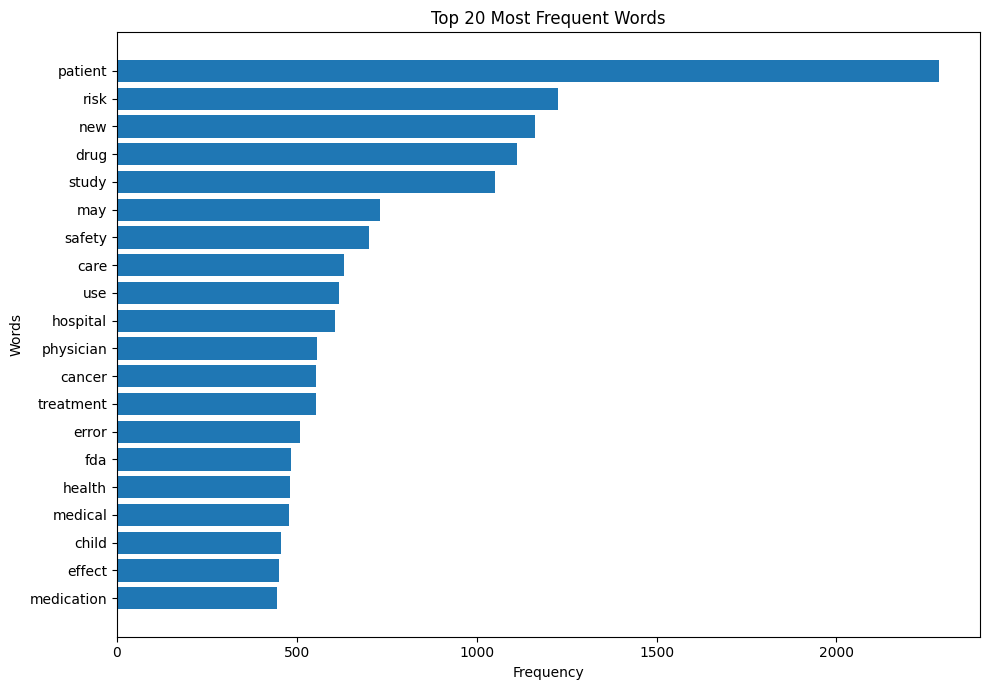

In [9]:
top20 = frequency_df.head(20).sort_values("Frequency")

plt.figure(figsize=(10, 7))
plt.barh(top20["Word"], top20["Frequency"])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words")
plt.tight_layout()
plt.show()

## Task 3: Topic Modelling using LDA

Convert the cleaned text into a document-term matrix and use LDA to identify the main topics in the healthcare headlines.

In [10]:
vectorizer = CountVectorizer(max_features=5000)
dtm = vectorizer.fit_transform(df["cleaned_text"])
feature_names = vectorizer.get_feature_names_out()

lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=20
)
lda_model.fit(dtm)

LatentDirichletAllocation(max_iter=20, n_components=5, random_state=42)

### Display the top 5 words per topic

In [11]:
for topic_index, topic in enumerate(lda_model.components_):
    top_words = [
        feature_names[i]
        for i in topic.argsort()[:-6:-1]
    ]
    print(f"Topic {topic_index + 1}: {', '.join(top_words)}")

Topic 1: hospital, hiv, risk, child, study
Topic 2: cancer, patient, treatment, new, study
Topic 3: patient, health, risk, medical, error
Topic 4: drug, fda, safety, risk, new
Topic 5: patient, care, safety, risk, surgery


### Visualize topics using pyLDAvis

In [12]:
import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa"
)
pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
